<a href="https://colab.research.google.com/github/miguelChimenes-commits/estudos-astropt/blob/main/PROJETOPY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
!git config --global user.name "miguelChimenes-commits"
!git config --global user.email "miguelchimenes528@gmail.com"

In [31]:
!git clone https://github.com/miguelChimenes-commits/estudos-astropt.git

fatal: destination path 'estudos-astropt' already exists and is not an empty directory.


In [32]:
%cd estudos-astropt/

/content/estudos-astropt


In [33]:
!git checkout main

Already on 'main'
Your branch is up to date with 'origin/main'.


In [2]:
!pip install astropy matplotlib urllib3 --quiet

import matplotlib.pyplot as teste
from astropy.io import fits
import urllib.request
import numpy as np

In [34]:
url_image = 'http://data.astropy.org/tutorials/FITS-images/HorseHead.fits'
image     = 'testes.fits'

print("CARREGANDO...")
urllib.request.urlretrieve(url_image, image)
print("SUCESSO!")

with fits.open(image) as lista_fits:

  matriz = lista_fits[0].data

CARREGANDO...
SUCESSO!


In [35]:
print("Tamanho da matriz: ")
print(matriz.shape)
print("Menor valor: ")
print(matriz.min())
print("Maior valor: ")
print(matriz.max())

Tamanho da matriz: 
(893, 891)
Menor valor: 
3759
Maior valor: 
22918


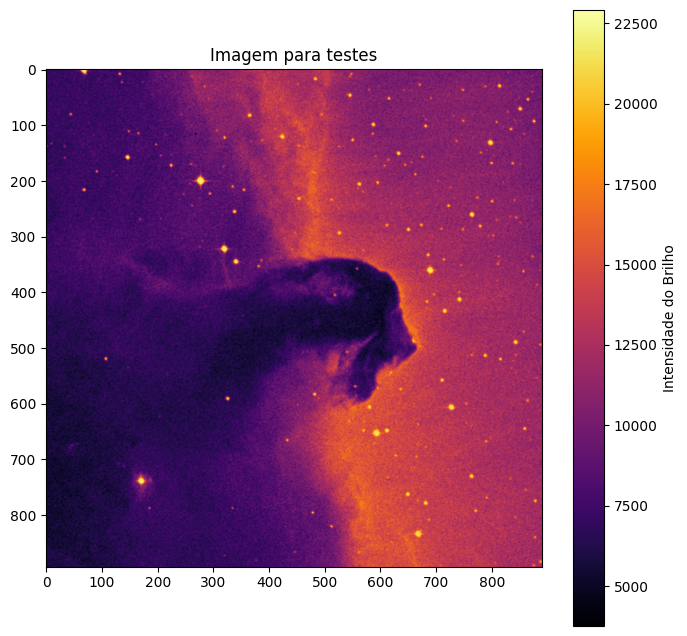

In [36]:
teste.figure(figsize=(8,8))
teste.imshow(matriz, cmap = "inferno")
teste.colorbar(label = "Intensidade do Brilho")
teste.title("Imagem para testes")
teste.show()

In [23]:
shape = (512, 512)
bias = np.random.normal(loc = 100, scale = 2, size = shape)
dark = bias + np.random.normal(loc = 50, scale = 1, size = shape)

y, x = np.indices(shape)
centro_y, centro_x = shape[0] // 2, shape[1] // 2

raio = np.sqrt((x - centro_x)**2 + (y - centro_y)**2)
raio_max = np.max(raio) if np.max(raio) != 0 else 1

vinheta = 1.0 - 0.3 * (raio / raio_max)
flat = (vinheta * 10000) + bias

estrela = np.zeros(shape)
estrela[256, 256] = 50000
estrela[100, 150] = 35000
estrela[400, 300] = 45000
light = (estrela + 300) * vinheta + dark

flat_corrigido = flat - bias

flat_normalizado = flat_corrigido / np.median(flat_corrigido)

imagem_final = (light - dark) / flat_normalizado


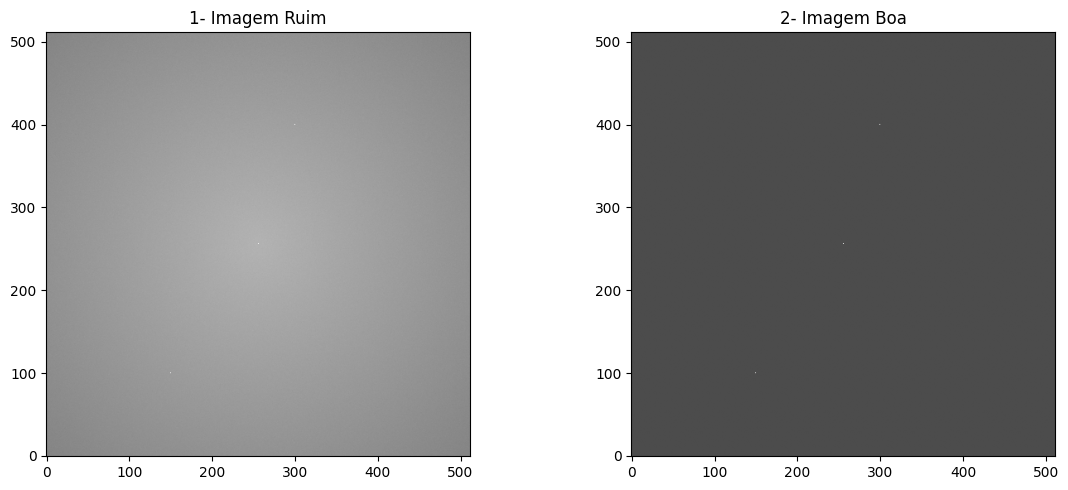

Média da imagem:  401.75 ADU
Média da imagem calibrada (limpa):  249.63 ADU


In [24]:
fig, axes = teste.subplots(1, 2, figsize = (12, 5))

axes[0].imshow(light, cmap = "gray", origin = "lower", vmin = 100, vmax = 600)
axes[0].set_title("1- Imagem Ruim")

axes[1].imshow(imagem_final, cmap = "gray", origin = "lower", vmin = 100, vmax = 600)
axes[1].set_title("2- Imagem Boa")

teste.tight_layout()
teste.show()

print(f"Média da imagem: {np.mean(light): .2f} ADU")
print(f"Média da imagem calibrada (limpa): {np.mean(imagem_final): .2f} ADU")


In [39]:
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')
repo_url = f"https://{token}@github.com/miguelChimenes-commits/estudos-astropt.git"

!git add .

!git commit -m "Segurança GitH"

!git push {repo_url} main


On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date
